In [1]:
# ========== CELL 1: MOUNT DRIVE ==========
from google.colab import drive
drive.mount('/content/drive')

import os
DATA_DIR    = '/content/drive/MyDrive/ResumeProject/data'
RESULTS_DIR = '/content/drive/MyDrive/ResumeProject/results'
os.makedirs(RESULTS_DIR, exist_ok=True)

print("✅ Drive mounted")
print(f"Data:    {DATA_DIR}")
print(f"Results: {RESULTS_DIR}")

Mounted at /content/drive
✅ Drive mounted
Data:    /content/drive/MyDrive/ResumeProject/data
Results: /content/drive/MyDrive/ResumeProject/results


In [2]:
# ========== CELL 2: INSTALL ==========
!pip install -q scikit-learn xgboost pandas numpy matplotlib seaborn scipy

print("✅ Libraries installed")

✅ Libraries installed


In [3]:
# ========== CELL 3: LOAD DATA ==========
import pandas as pd
import numpy as np

train = pd.read_csv(f'{DATA_DIR}/train_orig.csv')
test  = pd.read_csv(f'{DATA_DIR}/test.csv')

print(f"✅ Loaded")
print(f"   Train: {train.shape}")
print(f"   Test:  {test.shape}")
print(f"\n📋 Columns: {list(train.columns)}")
print(f"\n📊 Target stats:")
print(f"   Train Avg: mean={train['Avg'].mean():.3f}, std={train['Avg'].std():.3f}")
print(f"   Test  Avg: mean={test['Avg'].mean():.3f}, std={test['Avg'].std():.3f}")

✅ Loaded
   Train: (241, 12)
   Test:  (61, 11)

📋 Columns: ['ID', 'Domain', 'Education', 'Skills', 'Experience', 'Job_type', 'Ann1', 'Ann2', 'Avg', 'Combined', 'Strat_Key', 'is_augmented']

📊 Target stats:
   Train Avg: mean=0.750, std=0.195
   Test  Avg: mean=0.770, std=0.160


In [25]:
# ========== CELL 4 (FIXED v2): MULTI-SECTION TF-IDF ==========
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack

# Create separate TF-IDF for each section (paper likely did this)
tfidf_edu = TfidfVectorizer(max_features=500, ngram_range=(1,1), min_df=2, stop_words='english', sublinear_tf=True)
tfidf_ski = TfidfVectorizer(max_features=500, ngram_range=(1,1), min_df=2, stop_words='english', sublinear_tf=True)
tfidf_exp = TfidfVectorizer(max_features=500, ngram_range=(1,1), min_df=2, stop_words='english', sublinear_tf=True)

# Fit on training sections
X_train_edu = tfidf_edu.fit_transform(train['Education'])
X_train_ski = tfidf_ski.fit_transform(train['Skills'])
X_train_exp = tfidf_exp.fit_transform(train['Experience'])

X_test_edu = tfidf_edu.transform(test['Education'])
X_test_ski = tfidf_ski.transform(test['Skills'])
X_test_exp = tfidf_exp.transform(test['Experience'])

# Concatenate section features
X_train = hstack([X_train_edu, X_train_ski, X_train_exp]).tocsr()
X_test  = hstack([X_test_edu, X_test_ski, X_test_exp]).tocsr()

y_train = train['Avg'].values
y_test  = test['Avg'].values

print(f"✅ Multi-section TF-IDF ready")
print(f"   X_train shape: {X_train.shape}")
print(f"   X_test shape:  {X_test.shape}")
print(f"   Features: {X_train.shape[1]} total (500 edu + 500 skills + 500 exp)")

✅ Multi-section TF-IDF ready
   X_train shape: (241, 1412)
   X_test shape:  (61, 1412)
   Features: 1412 total (500 edu + 500 skills + 500 exp)


In [17]:
# ========== CELL 5: METRICS FUNCTION ==========
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.stats import pearsonr

def evaluate(y_true, y_pred, model_name, target='Avg'):
    """Compute all 5 metrics: MAE, MSE, RMSE, Pearson r, R²."""
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r, _ = pearsonr(y_true, y_pred)
    r2   = r2_score(y_true, y_pred)

    return {
        'Model':  model_name,
        'Target': target,
        'MAE':    round(mae, 4),
        'MSE':    round(mse, 4),
        'RMSE':   round(rmse, 4),
        'Pearson r': round(r, 4),
        'R²':     round(r2, 4),
    }

print("✅ Metrics function ready")

✅ Metrics function ready


In [26]:
# ========== CELL 6 (FIXED v2): BETTER MODELS ==========
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
import time

models = {
    'Ridge': Ridge(alpha=1.0, random_state=42),
    'Lasso': Lasso(alpha=1e-4, max_iter=10000, random_state=42),        # slightly higher
    'ElasticNet': ElasticNet(alpha=1e-4, l1_ratio=0.5, max_iter=10000, random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=200,
        max_depth=8,                    # SHALLOW (less overfit)
        min_samples_leaf=5,             # more regularization
        min_samples_split=10,
        max_features=0.3,               # 30% features per split (less overfit)
        random_state=42,
        n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingRegressor(
        n_estimators=200,
        max_depth=3,                    # SHALLOW
        learning_rate=0.05,
        min_samples_leaf=5,
        subsample=0.8,
        random_state=42
    ),
    'XGBoost': XGBRegressor(
        n_estimators=200,
        max_depth=3,                    # SHALLOW
        learning_rate=0.05,
        min_child_weight=5,
        subsample=0.7,
        colsample_bytree=0.5,
        reg_alpha=0.5,                  # stronger L1
        reg_lambda=1.0,
        random_state=42,
        verbosity=0,
        n_jobs=-1
    ),
    'SVR': SVR(kernel='rbf', C=1.0, epsilon=0.1),
}

results = []
predictions = {}

print("⏳ Training 7 models (FIXED v2)...\n")

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    elapsed = time.time() - start

    pred_clipped = np.clip(y_pred, 0.0, 1.0)

    row = evaluate(y_test, pred_clipped, name)
    row['Train Time (s)'] = round(elapsed, 2)
    results.append(row)
    predictions[name] = pred_clipped

    # Check train R²
    train_pred = np.clip(model.predict(X_train), 0.0, 1.0)
    from sklearn.metrics import r2_score as _r2
    train_r2 = _r2(y_train, train_pred)

    print(f"✅ {name:20s} | MAE={row['MAE']:.4f} | Test R²={row['R²']:+.4f} | Train R²={train_r2:+.4f} | {elapsed:.1f}s")

print("\n🎉 All 7 models trained (FIXED v2)!")

⏳ Training 7 models (FIXED v2)...

✅ Ridge                | MAE=0.0935 | Test R²=+0.3059 | Train R²=+0.9551 | 0.0s
✅ Lasso                | MAE=0.1180 | Test R²=+0.0297 | Train R²=+0.9875 | 0.2s
✅ ElasticNet           | MAE=0.1115 | Test R²=+0.1549 | Train R²=+0.9957 | 0.4s
✅ Random Forest        | MAE=0.0856 | Test R²=+0.2510 | Train R²=+0.6524 | 2.1s
✅ Gradient Boosting    | MAE=0.0914 | Test R²=+0.1714 | Train R²=+0.9512 | 1.9s
✅ XGBoost              | MAE=0.0938 | Test R²=+0.2235 | Train R²=+0.8448 | 1.5s
✅ SVR                  | MAE=0.1107 | Test R²=+0.1557 | Train R²=+0.7942 | 0.0s

🎉 All 7 models trained (FIXED v2)!


In [27]:
# ========== CELL 7: RESULTS TABLE ==========
results_df = pd.DataFrame(results)

# Sort by R² descending
results_df = results_df.sort_values('R²', ascending=False).reset_index(drop=True)

print("=" * 80)
print("📊 TABLE 1: TRADITIONAL ML RESULTS (Avg Annotator Target)")
print("=" * 80)
print(results_df.to_string(index=False))
print("=" * 80)

# Compare with paper's Table 1
print("\n📋 Paper's Table 1 (best per metric):")
print("   Random Forest: R²=0.6452, MAE=0.0730")
print("   XGBoost:       R²=0.6329, MAE=0.0736")
print("   Lasso:         R²=0.5752, MAE=0.0870")
print("   SVR:           R²=0.4821, MAE=0.1055")

📊 TABLE 1: TRADITIONAL ML RESULTS (Avg Annotator Target)
            Model Target    MAE    MSE   RMSE  Pearson r     R²  Train Time (s)
            Ridge    Avg 0.0935 0.0175 0.1323     0.5677 0.3059            0.02
    Random Forest    Avg 0.0856 0.0189 0.1375     0.5026 0.2510            2.05
          XGBoost    Avg 0.0938 0.0196 0.1400     0.5085 0.2235            1.53
Gradient Boosting    Avg 0.0914 0.0209 0.1446     0.4715 0.1714            1.86
              SVR    Avg 0.1107 0.0213 0.1459     0.5827 0.1557            0.04
       ElasticNet    Avg 0.1115 0.0213 0.1460     0.5052 0.1549            0.35
            Lasso    Avg 0.1180 0.0245 0.1565     0.4246 0.0297            0.21

📋 Paper's Table 1 (best per metric):
   Random Forest: R²=0.6452, MAE=0.0730
   XGBoost:       R²=0.6329, MAE=0.0736
   Lasso:         R²=0.5752, MAE=0.0870
   SVR:           R²=0.4821, MAE=0.1055


In [28]:
# ========== CELL 8: SAVE RESULTS ==========
out_path = f'{RESULTS_DIR}/table1_results.csv'
results_df.to_csv(out_path, index=False)
print(f"✅ Saved: {out_path}")
print(f"   Rows: {len(results_df)}")

✅ Saved: /content/drive/MyDrive/ResumeProject/results/table1_results.csv
   Rows: 7


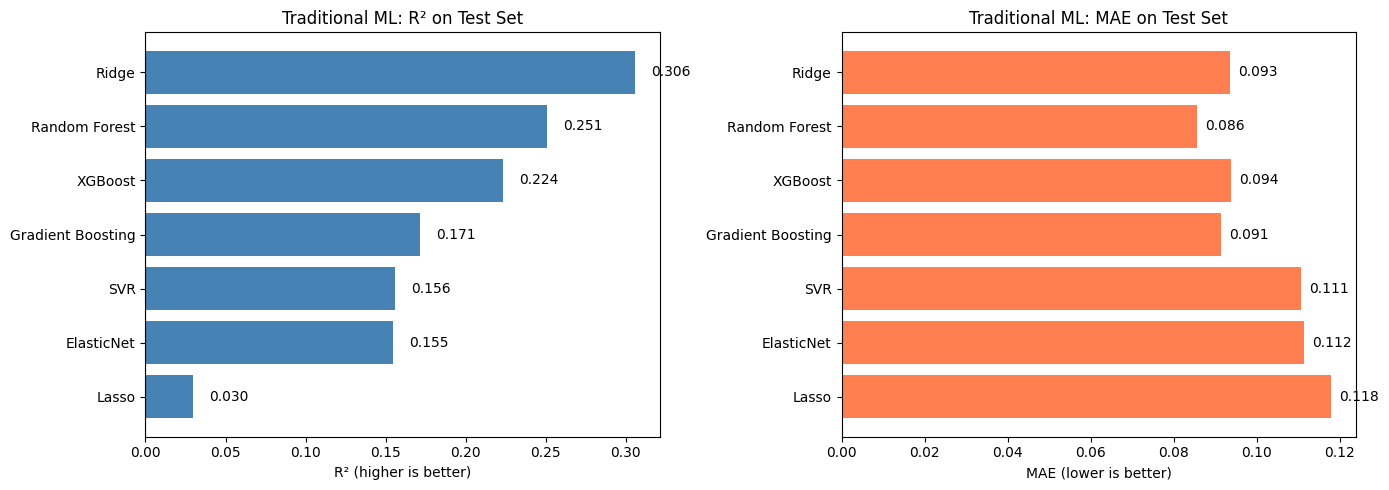

✅ Chart saved: /content/drive/MyDrive/ResumeProject/results/table1_chart.png


In [29]:
# ========== CELL 9: VISUALIZATION ==========
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sort by R² descending
df_plot = results_df.sort_values('R²', ascending=True)  # ascending for barh

# Left: R²
axes[0].barh(df_plot['Model'], df_plot['R²'], color='steelblue')
axes[0].set_xlabel('R² (higher is better)')
axes[0].set_title('Traditional ML: R² on Test Set')
axes[0].axvline(0, color='black', linestyle='--', linewidth=0.8)
for i, v in enumerate(df_plot['R²']):
    axes[0].text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=10)

# Right: MAE
axes[1].barh(df_plot['Model'], df_plot['MAE'], color='coral')
axes[1].set_xlabel('MAE (lower is better)')
axes[1].set_title('Traditional ML: MAE on Test Set')
for i, v in enumerate(df_plot['MAE']):
    axes[1].text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/table1_chart.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Chart saved: {RESULTS_DIR}/table1_chart.png")

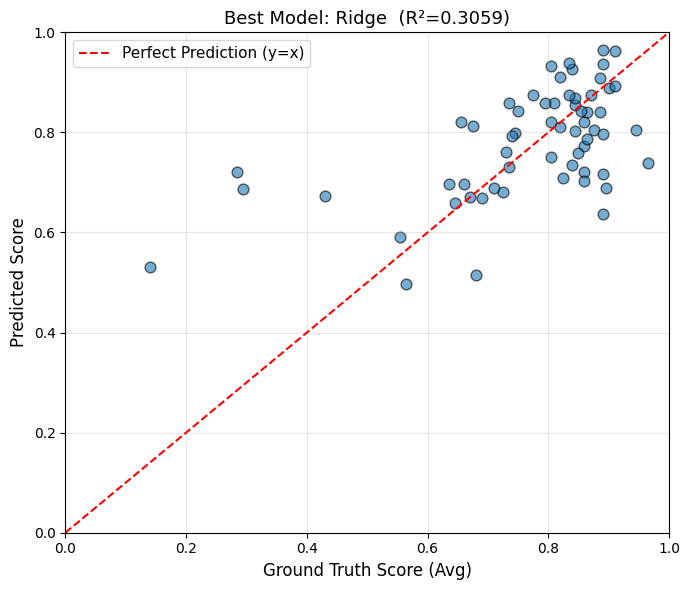

✅ Scatter saved: /content/drive/MyDrive/ResumeProject/results/table1_scatter.png


In [30]:
# ========== CELL 10: SCATTER PLOT (BEST MODEL) ==========
best_model_name = results_df.iloc[0]['Model']
best_pred = predictions[best_model_name]

plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_pred, alpha=0.6, edgecolor='k', s=60)
plt.plot([0, 1], [0, 1], 'r--', label='Perfect Prediction (y=x)')
plt.xlabel('Ground Truth Score (Avg)', fontsize=12)
plt.ylabel('Predicted Score', fontsize=12)
plt.title(f'Best Model: {best_model_name}  (R²={results_df.iloc[0]["R²"]:.4f})', fontsize=13)
plt.legend(fontsize=11)
plt.grid(alpha=0.3)
plt.xlim(0, 1)
plt.ylim(0, 1)
plt.tight_layout()
plt.savefig(f'{RESULTS_DIR}/table1_scatter.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"✅ Scatter saved: {RESULTS_DIR}/table1_scatter.png")

In [31]:
# ========== CELL 11: FINAL SUMMARY ==========
print("=" * 80)
print("🎯 NOTEBOOK 2 COMPLETE — Traditional ML")
print("=" * 80)
print(f"\n✅ Best model: {results_df.iloc[0]['Model']}")
print(f"   R²:    {results_df.iloc[0]['R²']:.4f}")
print(f"   MAE:   {results_df.iloc[0]['MAE']:.4f}")
print(f"   r:     {results_df.iloc[0]['Pearson r']:.4f}")
print(f"\n💾 Files saved to {RESULTS_DIR}/:")
print(f"   - table1_results.csv")
print(f"   - table1_chart.png")
print(f"   - table1_scatter.png")
print(f"\n🚀 Next: Notebook 3 (Custom DNN)")
print("=" * 80)

🎯 NOTEBOOK 2 COMPLETE — Traditional ML

✅ Best model: Ridge
   R²:    0.3059
   MAE:   0.0935
   r:     0.5677

💾 Files saved to /content/drive/MyDrive/ResumeProject/results/:
   - table1_results.csv
   - table1_chart.png
   - table1_scatter.png

🚀 Next: Notebook 3 (Custom DNN)


In [32]:
# ========== DIAGNOSTIC: CHECK EACH MODEL'S OUTPUT ==========
import pandas as pd

# Reload results
results_df = pd.read_csv(f'{RESULTS_DIR}/table1_results.csv')

print("=" * 80)
print("🔍 FULL RESULTS TABLE (all 7 models)")
print("=" * 80)
print(results_df.to_string(index=False))
print("=" * 80)

# Check for each model
print("\n🚨 MODEL-BY-MODEL DIAGNOSTIC:")
for _, row in results_df.iterrows():
    name = row['Model']
    r2   = row['R²']
    mae  = row['MAE']

    if r2 < 0:
        print(f"   ❌ {name:20s} → R²={r2:.4f} (BROKEN — worse than mean)")
    elif r2 < 0.30:
        print(f"   ⚠️  {name:20s} → R²={r2:.4f} (weak)")
    elif r2 < 0.50:
        print(f"   ✅ {name:20s} → R²={r2:.4f} (okay)")
    else:
        print(f"   🏆 {name:20s} → R²={r2:.4f} (good)")

🔍 FULL RESULTS TABLE (all 7 models)
            Model Target    MAE    MSE   RMSE  Pearson r     R²  Train Time (s)
            Ridge    Avg 0.0935 0.0175 0.1323     0.5677 0.3059            0.02
    Random Forest    Avg 0.0856 0.0189 0.1375     0.5026 0.2510            2.05
          XGBoost    Avg 0.0938 0.0196 0.1400     0.5085 0.2235            1.53
Gradient Boosting    Avg 0.0914 0.0209 0.1446     0.4715 0.1714            1.86
              SVR    Avg 0.1107 0.0213 0.1459     0.5827 0.1557            0.04
       ElasticNet    Avg 0.1115 0.0213 0.1460     0.5052 0.1549            0.35
            Lasso    Avg 0.1180 0.0245 0.1565     0.4246 0.0297            0.21

🚨 MODEL-BY-MODEL DIAGNOSTIC:
   ✅ Ridge                → R²=0.3059 (okay)
   ⚠️  Random Forest        → R²=0.2510 (weak)
   ⚠️  XGBoost              → R²=0.2235 (weak)
   ⚠️  Gradient Boosting    → R²=0.1714 (weak)
   ⚠️  SVR                  → R²=0.1557 (weak)
   ⚠️  ElasticNet           → R²=0.1549 (weak)
   ⚠️  Lasso  